# Imports

In [2]:
import subprocess
import os
import glob
import sys
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)

from rstools import RSoftCircuit

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import linecache
from tqdm import tqdm

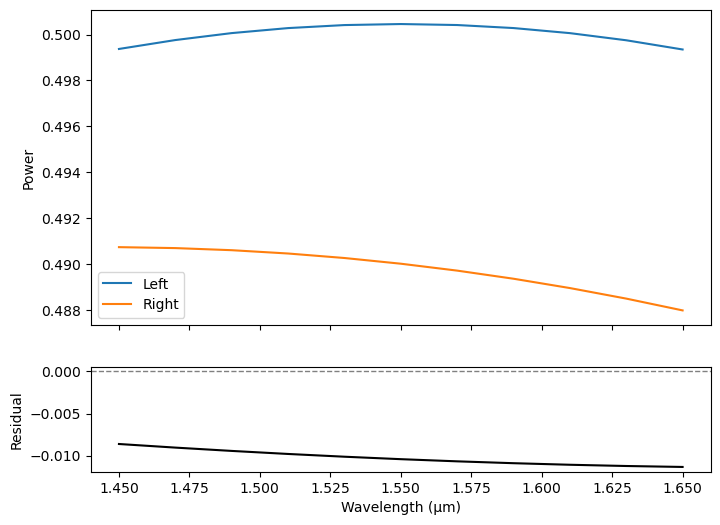

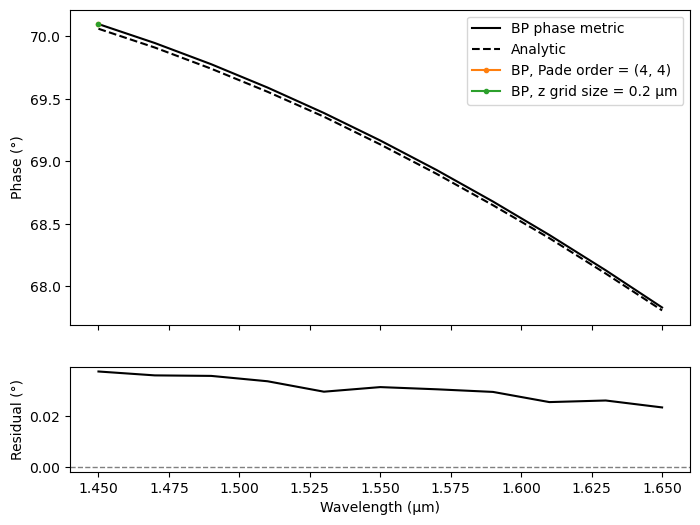

In [23]:
import pandas as pd
import os, sys
sys.path.append("D:\\DATA\\ActivePIC")
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit
import rsoft_lib as rlib

working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
filename_root = "TwoWaveguides"
save_dir = f"{working_dir}TwoWaveguides_widthTest_scan_Wav\\"
table_filename = 'D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_neff_table\StraightWaveguide_neff_long_fullWavelengthRange.csv'
df_neff = pd.read_csv(table_filename)
wav_arr = np.linspace (1.45, 1.65, 11)

monitors, phase_diff_expected = [], []
for wav in wav_arr:
    match = df_neff[np.isclose(df_neff['wavelength'], wav) & np.isclose(df_neff['width'], 3.40)]
    neff_left = match.iloc[0]['neff']
    match = df_neff[np.isclose(df_neff['wavelength'], wav) & np.isclose(df_neff['width'], 5.0)]
    neff_right = match.iloc[0]['neff']
    phase_diff_expected.append((2*np.pi/wav * (neff_right - neff_left) * 100) * 180/np.pi)

    wav_str = f"{wav:0.3f}".replace(".", "p")
    monitor_filename = f'{save_dir}{filename_root}_widthTest_scan_Wav{wav_str}.mon'
    monitor = rlib.read_monitor(monitor_filename)
    # if np.isclose(wav, 1.45):
    #     test_grid = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_gridSize0p05_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon').values[-1]
    #     test_pade0 = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_pade44_Direct_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon')
    #     test_pade0 = test_pade0.values[np.isclose(test_pade0.z, 100.0)].flatten()
    if np.isclose(wav, 1.45):
        test_pade1 = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_pade44_Direct_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon')
        test_pade1 = test_pade1.values[np.isclose(test_pade1.z, 100.0)].flatten()
        test_grid = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_gridZ0p2_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon')
        test_grid = test_grid.values[np.isclose(test_grid.z, 100.0)].flatten()
        
    monitors.append(monitor.values[np.isclose(monitor.z, 100.0)].flatten())
monitors = np.array(monitors)
phase_diff_expected = np.array(phase_diff_expected)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(wav_arr, monitors[:,0], label='Left', color='C0')
ax1.plot(wav_arr, monitors[:,2], label='Right', color='C1')
ax1.set_ylabel('Power')
ax1.legend()
 
residual = monitors[:,2] - monitors[:,0]
ax2.plot(wav_arr, residual, color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('Residual')
plt.show()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 

phase_diff_monitor = (monitors[:,3] - monitors[:,1])%360
ax1.plot(wav_arr, phase_diff_monitor, 'k', label='BP phase metric')
ax1.plot(wav_arr, phase_diff_expected, 'k--', label='Analytic')
# ax1.plot([1.45], [test_grid[3]-test_grid[1]], color='C0', marker='o', label='BP, Grid size = 0.05 μm')
# ax1.plot([1.45], [test_pade0[3]-test_pade0[1]], color='C1', marker='o', label='BP, Pade order = (4, 4)')
ax1.plot([1.45], [test_pade1[3]-test_pade1[1]], color='C1', marker='.', label='BP, Pade order = (4, 4)')
ax1.plot([1.45], [test_grid[3]-test_grid[1]], color='C2', marker='.', label='BP, z grid size = 0.2 μm')
ax1.set_ylabel('Phase (°)')
ax1.legend()
 
residual = phase_diff_monitor - phase_diff_expected
residual[residual > 180] = residual[residual > 180] - 360 
residual[residual < -180] = residual[residual < -180] + 360 
ax2.plot(wav_arr, residual, color='k')
# ax2.plot(wav_arr, phase_diff_expected, color='k', linestyle='dashed')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('Residual (°)')
 
# # Inset: zoom into the last 0.1 microns of z
# z_max = monitors.z.max()
# axins = inset_axes(ax1, width="35%", height="45%", loc='upper left', borderpad=2)
 
# mask = monitors.z >= (z_max - 0.1)
# axins.plot(monitors.z, residual, color='k')
# axins.axhline(0, color='grey', linestyle='dashed', linewidth=1)
# axins.set_xlim(z_max - 0.01, z_max+0.01)
# # axins.set_ylim(179, 181)
 
plt.show()


# Scan straight waveguide in wavelength

In [2]:
device_name = "StraightWaveguide"
working_dir = f"C:\\Users\\runner\\ActivePIC\\{device_name}\\"
save_dir = f"{device_name}_scan_Wav"
filename = f"{device_name}.ind"
wav_arr = np.linspace(1.45, 1.65, 51)

# Make scan save directory if it doesn't exist
os.makedirs(f"{working_dir}/{save_dir}/", exist_ok=True)

# Conduct scan
for wav in tqdm(wav_arr):
    # Set wavelength in .ind file
    c = RSoftCircuit()
    c.read(working_dir+filename)
    c.set_symbol("free_space_wavelength", wav)
    c.write(working_dir+filename)
    
    # Define the command and arguments
    wav_str = f"{wav:0.3f}".replace(".", "p")
    command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{save_dir}{wav_str}", "wait=0"]

    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

100%|██████████████████████████████████████████████████████████████████████████████████| 51/51 [06:46<00:00,  7.97s/it]


In [5]:
device_name = "ParallelWaveguides"
working_dir = f"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\"
save_dir = f"{device_name}_scan_Wav_Length"
filename = f"{device_name}.ind"
wav_arr = np.linspace(1.45, 1.65, 11)
length_arr = [100, 200, 500, 1000, 27000, 28540]

# Make scan save directory if it doesn't exist
os.makedirs(f"{working_dir}/{save_dir}/", exist_ok=True)

# Conduct scan
for wav in tqdm(wav_arr):
    for length in length_arr:
        # Set wavelength in .ind file
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("Length", length)
        c.write(working_dir+filename)
        
        # Define the command and arguments
        wav_str = f"{wav:0.3f}".replace(".", "p")
        length_str = f"{length:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{device_name}_scan_Wav{wav_str}_Length{length_str}", "wait=0"]
    
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

np.save(f'{working_dir}{save_dir}\\{device_name}_wav', wav_arr)
np.save(f'{working_dir}{save_dir}\\{device_name}_length', length_arr)

100%|███████████████████████████████████████████████████████████████████████████████| 11/11 [1:14:21<00:00, 405.55s/it]


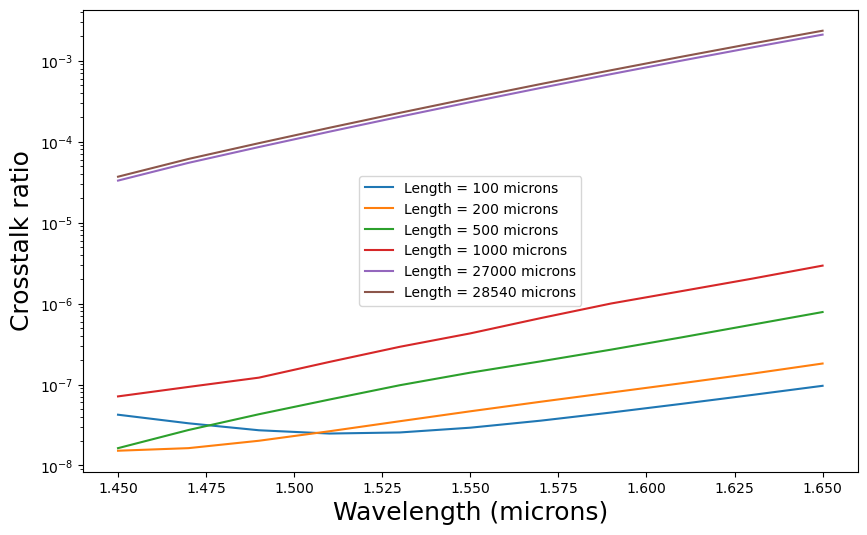

In [7]:
device_name = 'ParallelWaveguides'
working_dir = f"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\"
save_dir = f"{device_name}_scan_Wav_Length"
wav_arr = np.load(f"{working_dir}{save_dir}\\{device_name}_wav.npy")
length_arr = np.load(f"{working_dir}{save_dir}\\{device_name}_length.npy")#[1:]
fontsize = 18

powers_left, powers_right = [], []
for wav in wav_arr:
    wav_str = f"{wav:0.3f}".replace(".", "p")
    left, right = [], []
    for length in length_arr:
        length_str = f"{length:0.3f}".replace(".", "p")
        filename = f"{working_dir}{save_dir}\\{device_name}_scan_Wav{wav_str}_Length{length_str}.mon"
        data = np.genfromtxt(filename, delimiter='', skip_header=5)
        left.append(data[-1, 1])
        right.append(data[-1, 2])
    powers_left.append(left)
    powers_right.append(right)
powers_left, powers_right = np.array(powers_left), np.array(powers_right)

# Plot loss
fig, ax = plt.subplots(1, 1, figsize=(10,6))
for i in range(len(length_arr)):
    plt.plot(wav_arr, powers_right[:, i]/powers_left[:, i], color=f'C{i}', label=f'Length = {length_arr[i]} microns')
plt.yscale('log')
plt.xlabel('Wavelength (microns)', fontsize=fontsize)
plt.ylabel('Crosstalk ratio', fontsize=fontsize)
plt.legend()
plt.show()

np.save(f'{working_dir}{save_dir}\\{device_name}_power_left', powers_left)
np.save(f'{working_dir}{save_dir}\\{device_name}_power_right', powers_right)

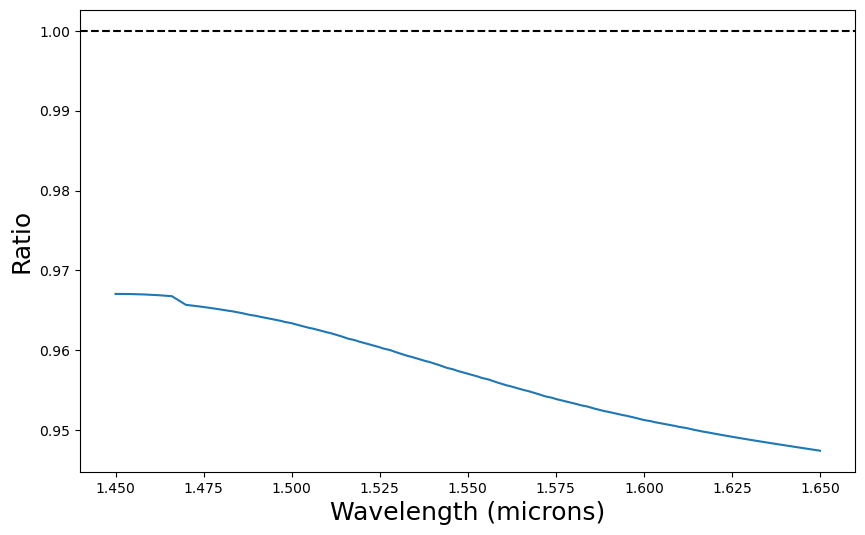

In [30]:
device_name = 'SbendWaveguide'
working_dir = f"C:\\Users\\runner\\ActivePIC\\{device_name}\\"
save_dir = f"{device_name}_scan_Wav"
fontsize = 18

filenames_mon = glob.glob(working_dir+save_dir+"\*[0-9].mon")
wav_sbend, power_sbend = [], []

for filename in filenames_mon:
    data = np.genfromtxt(filename, delimiter='', skip_header=5)
    wav_sbend.append(float(filename.split('Wav')[-1].split('.')[0].replace('p', '.')))
    power_sbend.append(data[-1, 1])
wav_sbend, power_sbend = np.array(wav_sbend), np.array(power_sbend)

device_name = 'StraightWaveguide'
working_dir = f"C:\\Users\\runner\\ActivePIC\\{device_name}\\"
save_dir = f"{device_name}_scan_Wav"
fontsize = 18

filenames_mon = glob.glob(working_dir+save_dir+"\*[0-9].mon")
wav_straight, power_straight = [], []

for filename in filenames_mon:
    data = np.genfromtxt(filename, delimiter='', skip_header=5)
    wav_straight.append(float(filename.split('Wav')[-1].split('.')[0].replace('p', '.')))
    power_straight.append(data[-1, 1])
wav_straight, power_straight = np.array(wav_straight), np.array(power_straight)

# Plot loss
fig, ax = plt.subplots(1, 1, figsize=(10,6))
plt.plot(wav_straight, power_sbend/power_straight)
plt.axhline(1, linestyle='dashed', color='k')
plt.xlabel('Wavelength (microns)', fontsize=fontsize)
plt.ylabel('Ratio', fontsize=fontsize)
plt.show()